# K1: Sea-level-rise exposure on FloodWatch hexes

**Task K1** from the team's delegation plan (`docs/delegation_plan_kai.md`): for every H3 hex in the
West Oakland study area, report the share of land flooded and the buildings and residents affected at
0–5 ft of sea-level rise, so FloodWatch can show **today's rain flooding** next to **future sea-level-rise flooding**.

- The numbers come from `pipeline/10_floodwatch_slr.py` (run by `pipeline/run_all.sh`), which writes
  `data/processed/floodwatch/hex_slr.csv` and checks that hex sums equal the `stats.json` totals.
- This notebook explores the result and joins it with FloodWatch's rain-flooding scores
  (`oakland-flood-vulnerability/outputs/hex_scores.csv`).
- Hexes are H3 resolution 9 (~0.1 km²), the same grid FloodWatch uses, so the two join on the `h3` id.
- Scenarios are feet above today's high tide (MHHW). "5 ft" uses ART's 66 in (5.5 ft) map, the team's
  conservative choice. Depth, residents and building heights are estimates (see the README).

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Polygon

ROOT = Path.cwd().resolve().parents[1]          # notebooks/ -> oakland-flood-vulnerability/ -> repo
FW = ROOT / "data" / "processed" / "floodwatch"
slr = pd.read_csv(FW / "hex_slr.csv")
check = json.loads((FW / "hex_slr_check.json").read_text())
fw = pd.read_csv(ROOT / "oakland-flood-vulnerability" / "outputs" / "hex_scores.csv")
print(f"{slr.h3.nunique()} study-area hexes; {check['n_hexes_in_floodwatch']} of them are also scored by FloodWatch")

290 study-area hexes; 255 of them are also scored by FloodWatch


## 1. Reconciliation with `stats.json` (the K1 *done when* check)

In [2]:
rows = []
for c in check["scenarios"]:
    rows.append({"scenario": c["scenario"],
                 "buildings (hex sum / stats)": "{} / {}".format(*c["buildings_flooded"]),
                 "residents (hex sum / stats)": "{} / {}".format(*c["residents_affected"]),
                 "flooded land km² (hex sum / stats)": "{} / {}".format(*c["flooded_land_km2"]),
                 "match": "✓" if c["ok"] else "✗"})
pd.DataFrame(rows).set_index("scenario")

,buildings (hex sum / stats),residents (hex sum / stats),flooded land km² (hex sum / stats),match
scenario,,,,
0ft,0 / 0,0 / 0,0.0 / 0.0,✓
1ft,6 / 6,8 / 8,0.3013 / 0.3013,✓
2ft,14 / 14,8 / 8,0.4261 / 0.4261,✓
3ft,49 / 49,907 / 907,0.8575 / 0.8575,✓
4ft,117 / 117,1341 / 1341,1.5274 / 1.5274,✓
5ft,1137 / 1137,7689 / 7689,5.7888 / 5.7888,✓


## 2. How many hexes flood at each level?

In [3]:
per = (slr.groupby(["scenario", "slr_ft"])
       .agg(hexes_with_flooded_land=("flooded_land_m2", lambda s: int((s > 0).sum())),
            hexes_with_flooded_buildings=("buildings_flooded", lambda s: int((s > 0).sum())),
            buildings_flooded=("buildings_flooded", "sum"),
            residents_affected=("residents_affected", "sum"))
       .reset_index().sort_values("slr_ft").set_index("scenario").drop(columns="slr_ft"))
per["residents_affected"] = per.residents_affected.round().astype(int)
per

,hexes_with_flooded_land,hexes_with_flooded_buildings,buildings_flooded,residents_affected
scenario,,,,
0ft,0,0,0,0
1ft,78,5,6,8
2ft,83,9,14,8
3ft,91,17,49,907
4ft,96,25,117,1341
5ft,161,85,1137,7689


## 3. Today's rain flooding vs future sea-level-rise flooding
FloodWatch covers the City of Oakland only, so study-area hexes in Alameda and Emeryville have SLR numbers
but no FloodWatch score.

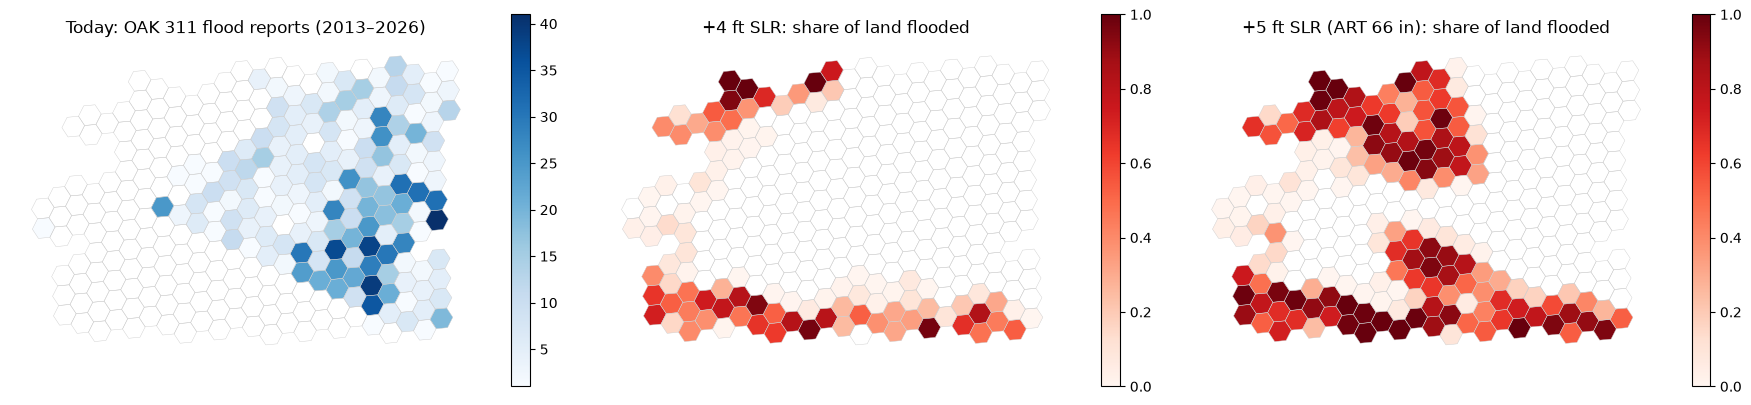

In [4]:
wide = slr.pivot_table(index="h3", columns="scenario", values="flooded_share").add_prefix("share_")
wide = wide.join(slr.pivot_table(index="h3", columns="scenario", values="residents_affected").add_prefix("res_"))
both = wide.join(fw.set_index("h3")[["fvi", "hazard", "vulnerability", "flood_reports", "why"]], how="left")

def hex_poly(c):
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])

g = gpd.GeoDataFrame(both, geometry=[hex_poly(c) for c in both.index], crs=4326)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
panels = [("flood_reports", "Today: OAK 311 flood reports (2013–2026)", "Blues", None),
          ("share_4ft", "+4 ft SLR: share of land flooded", "Reds", (0, 1)),
          ("share_5ft", "+5 ft SLR (ART 66 in): share of land flooded", "Reds", (0, 1))]
for ax, (col, title, cmap, lim) in zip(axes, panels):
    g.boundary.plot(ax=ax, color="#cccccc", linewidth=0.3)
    kw = dict(vmin=lim[0], vmax=lim[1]) if lim else {}
    g[g[col].fillna(0) > 0].plot(column=col, cmap=cmap, ax=ax, legend=True, legend_kwds={"shrink": 0.6}, **kw)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout()
out = ROOT / "oakland-flood-vulnerability" / "outputs" / "k1_today_vs_slr.png"
plt.savefig(out, dpi=130, bbox_inches="tight"); plt.show()

## 4. Double exposure: hexes that already flood in storms *and* flood with sea-level rise
These are the places where the combined story is strongest: "it already floods when it rains, and
sea-level rise makes it permanent."

In [5]:
in_fw = both[both.fvi.notna()]
for sid in ["3ft", "4ft", "5ft"]:
    slr_hit = in_fw[f"share_{sid}"] > 0
    rain_hit = in_fw.flood_reports > 0
    print(f"+{sid}: {int(slr_hit.sum())} FloodWatch hexes flood from SLR; "
          f"{int((slr_hit & rain_hit).sum())} of them already have 311 flood reports "
          f"({(slr_hit & rain_hit).sum() / max(1, slr_hit.sum()):.0%}); "
          f"vs {rain_hit.mean():.0%} of all study-area FloodWatch hexes")

double = in_fw[(in_fw.share_5ft > 0) & (in_fw.flood_reports > 0)].copy()
double["res_5ft"] = double.res_5ft.round(0)
double.sort_values(["share_5ft", "flood_reports"], ascending=False)[
    ["share_4ft", "share_5ft", "res_4ft", "res_5ft", "flood_reports", "fvi", "why"]].head(15).round(2)

+3ft: 63 FloodWatch hexes flood from SLR; 10 of them already have 311 flood reports (16%); vs 59% of all study-area FloodWatch hexes
+4ft: 65 FloodWatch hexes flood from SLR; 12 of them already have 311 flood reports (18%); vs 59% of all study-area FloodWatch hexes
+5ft: 127 FloodWatch hexes flood from SLR; 47 of them already have 311 flood reports (37%); vs 59% of all study-area FloodWatch hexes


,share_4ft,share_5ft,res_4ft,res_5ft,flood_reports,fvi,why
h3,,,,,,,
89283081103ffff,0.00,0.99,0.00,71.0,10.0,0.39,FEMA 500-yr floodplain; low spot (4 ft below t...
8928308110bffff,0.00,0.98,0.00,440.0,6.0,0.44,FEMA 500-yr floodplain; 6 flood reports
8928308144bffff,0.53,0.95,0.00,0.0,1.0,0.89,FEMA 100-yr floodplain; low spot (3 ft below t...
89283081473ffff,0.66,0.95,206.84,207.0,1.0,0.22,FEMA 100-yr floodplain; 1 flood reports
8928308111bffff,0.00,0.94,0.00,157.0,12.0,0.47,FEMA 500-yr floodplain; 12 flood reports
89283081563ffff,0.00,0.92,0.00,31.0,1.0,0.00,FEMA 500-yr floodplain; low spot (5 ft below t...
8928308144fffff,0.45,0.91,31.03,31.0,7.0,0.89,FEMA 500-yr floodplain; 7 flood reports; 24% n...
8928308157bffff,0.00,0.90,0.00,1.0,5.0,0.00,5 flood reports
89283081157ffff,0.00,0.89,0.00,28.0,15.0,0.39,15 flood reports


In [6]:
# Does today's rain-flood score predict where sea-level rise hits? (rank correlation, FloodWatch hexes)
from scipy.stats import spearmanr
for sid in ["4ft", "5ft"]:
    r, p = spearmanr(in_fw.fvi, in_fw[f"share_{sid}"])
    r2, p2 = spearmanr(in_fw.flood_reports, in_fw[f"share_{sid}"])
    print(f"+{sid}: Spearman FVI vs flooded share r={r:.2f} (p={p:.3f}); 311 reports vs flooded share r={r2:.2f} (p={p2:.3f})")

+4ft: Spearman FVI vs flooded share r=-0.31 (p=0.000); 311 reports vs flooded share r=-0.42 (p=0.000)
+5ft: Spearman FVI vs flooded share r=-0.34 (p=0.000); 311 reports vs flooded share r=-0.39 (p=0.000)


In [7]:
# Same test, residential hexes only (>= 50 estimated residents), so empty Port and shoreline land
# (no residents -> no 311 callers) doesn't drive the result.
res_tot = slr.drop_duplicates("h3").set_index("h3").residents_total
resid = in_fw[res_tot.reindex(in_fw.index).fillna(0) >= 50]
print(f"{len(resid)} residential FloodWatch hexes")
for sid in ["4ft", "5ft"]:
    r, p = spearmanr(resid.flood_reports, resid[f"share_{sid}"])
    hit = resid[f"share_{sid}"] > 0
    print(f"+{sid}: 311 reports vs flooded share r={r:.2f} (p={p:.3f}); mean reports in SLR-flooded hexes "
          f"{resid.loc[hit, 'flood_reports'].mean():.1f} vs {resid.loc[~hit, 'flood_reports'].mean():.1f} elsewhere")

135 residential FloodWatch hexes
+4ft: 311 reports vs flooded share r=-0.07 (p=0.403); mean reports in SLR-flooded hexes 9.9 vs 9.5 elsewhere
+5ft: 311 reports vs flooded share r=-0.20 (p=0.022); mean reports in SLR-flooded hexes 6.4 vs 10.9 elsewhere


### What this shows
- **Sea-level rise and today's reported rain flooding mostly hit different places.** SLR floods the Port,
  Jack London and the Emeryville shoreline first; 311 rain-flood reports cluster inland, in residential
  West Oakland and downtown. Across all hexes the rank correlation is negative (about -0.4).
- **This is not only a "nobody lives at the Port" effect.** Among residential hexes (>= 50 residents) there is
  no relationship at +4 ft (r = -0.07, n.s.), and at +5 ft SLR-flooded residential hexes have *fewer* reports
  on average (6.4 vs 10.9).
- **So the combined story should be told place by place, not as a city-wide pattern.** The 47 "double
  exposure" hexes at +5 ft (table above) are real places that already report storm-drain flooding and would
  also flood with sea-level rise; those are the ones to feature. The claim "the areas that flood in rain are
  the ones sea-level rise will hit" is not supported by this data.
- 311 reports depend on who calls, and the SLR layer is still water at high tide (no rainfall), so this
  comparison is suggestive. K3 (rain + tide) is the direct test of whether higher water makes drainage
  flooding worse.

## Notes and limitations
- **Assignment rules.** Each 1 m cell goes to the hex containing its center; each building goes to the hex
  containing its representative point, so a building straddling two hexes counts once. This is why the hex
  sums match `stats.json` exactly.
- **Edge hexes.** Hexes on the study-area edge are only partly inside the analysis grid (`grid_coverage < 1`);
  their `land_m2` and `flooded_share` describe only the part inside the grid.
- **Estimates.** Flood depth is estimated from LiDAR inside ART's extent, and residents per building are
  allocated from Census tract totals. Treat `residents_affected` per hex as approximate.
- **Two different hazards.** 311 reports measure rain and storm-drain flooding *reported by people*;
  the SLR layer is still-water flooding at high tide. Overlap is suggestive, not causal. Task K3
  (rain + tide) tests the link directly.